# 04 · 苍穹外卖：套餐管理

来源：`D:/baidudisk/BaiduNetdiskDownload/资料.rar` 中的 `资料/day04/项目实战-套餐管理.md`、`资料/day04/项目实战-套餐管理 - 参考答案.md` 及同目录 assets 配图。整理日期：2026-10-09。

本章接着第03章的菜品管理，完成新增套餐、分页查询、单个/批量删除、回显修改和起售停售。按已有笔记格式保留参考答案的30段代码、两张表结构和16张配图；原实战题也单独收录，补充解释、资料补全、勘误与测试清单分开标注。

参考答案的五处功能测试均写“略”，笔记补充可执行的验收矩阵。答案调用了未展示的 SetmealMapper.update；笔记从同一资料.rar的day12项目完整版中核对DTO、VO、update方法与SQL，作为独立资料补全单元说明。它们不替代day04原答案，原文件也未修改。

> **重点勘误。** 原新增仅复制DTO，没有在服务端保证默认停售；名称唯一、分类类型和菜品份数需要后端校验；批量插入列表名应明确；不存在的套餐会在删除/回显处出错；起售时空套餐或关联菜品已删除可能被放行；普通修改不能绕过专用起售校验。新增、修改和删除的事务已在答案中标注，跟练时保留。


## 跟练路线、接口与数据关系（补充）

| 顺序 | 功能 | 写入/读取要点 |
| --- | --- | --- |
| 1 | 新增套餐 | 校验套餐和菜品 → 插入setmeal回填id → 批量插入setmeal_dish |
| 2 | 套餐分页 | 按名称/分类/状态过滤，关联分类名称，PageHelper返回总数与本页 |
| 3 | 删除套餐 | 全部目标存在且停售，再在事务内删除关系和套餐 |
| 4 | 回显、修改 | 返回套餐及完整菜品关系；事务内改套餐、删旧关系、插入新关系 |
| 5 | 起售、停售 | status只允许0/1，起售前核对套餐内所有菜品 |

### 接口速查

| 功能 | 方法与后端路径 | 参数/返回 |
| --- | --- | --- |
| 套餐分类下拉框 | `GET /admin/category/list?type=2` | 沿用分类管理；type=2表示套餐分类 |
| 添加菜品的分类下拉框 | `GET /admin/category/list?type=1` | type=1表示菜品分类 |
| 按分类选择可售菜品 | `GET /admin/dish/list?categoryId=...` | 当前参考实现只查询status=1的菜品 |
| 图片上传 | `POST /admin/common/upload` | 沿用第03章，multipart字段file，返回图片URL |
| 新增套餐 | `POST /admin/setmeal` | JSON SetmealDTO，含setmealDishes |
| 分页查询 | `GET /admin/setmeal/page` | page、pageSize、name、categoryId、status |
| 单个/批量删除 | `DELETE /admin/setmeal?ids=1,2` | Query列表，单删也使用同一接口 |
| 回显套餐 | `GET /admin/setmeal/{id}` | 返回SetmealVO与菜品关系列表 |
| 修改套餐 | `PUT /admin/setmeal` | JSON SetmealDTO，必须含目标id |
| 起售/停售 | `POST /admin/setmeal/status/{status}?id=...` | status为Path参数，id为Query参数 |

以上是后端路径；管理页面的 `/api/...` 通常由Nginx转发成 `/admin/...`。管理端登录使用课程token请求头，身份与审计字段由拦截器/BaseContext提供。状态接口的id没有@RequestBody，不能仅把id放进JSON后认为参数已经绑定。

### 五张表的关联

```text
category(type=1).id ← dish.category_id
                       dish.id ← dish_flavor.dish_id
                       dish.id ← setmeal_dish.dish_id
                                   setmeal_dish.setmeal_id → setmeal.id
                                                            setmeal.category_id → category(type=2).id
```

一个套餐包含多个菜品，一个菜品也可以加入多个套餐，setmeal_dish把多对多关系转换为两组一对多。口味属于dish_flavor，本章套餐关系记录的是菜品id、名称、单价和copies，不在新增套餐时再插入口味。

| 对象 | 用途 | 核心区别 |
| --- | --- | --- |
| SetmealDTO | 新增/修改请求 | 包含setmealDishes，后端仍须校验 |
| Setmeal | setmeal表实体 | 保存套餐基础信息，不直接保存菜品集合 |
| SetmealDish | 关系表实体 | setmealId、dishId、菜品快照、copies |
| SetmealPageQueryDTO | 分页筛选 | page、pageSize与可选查询条件 |
| SetmealVO | 查询响应 | 多出categoryName与setmealDishes |

### 三个容易混淆的值

`setmeal.price`是整份套餐售价，不自动等于菜品单价×份数之和；`setmeal_dish.price`是关联菜品的冗余单价；`copies`是一份套餐包含该菜品几份。是否按成本限制套餐售价要由业务另行决定，资料没有提供这套计价政策。


## 项目实战题（资料原文）

完成套餐管理模块所有业务功能，包括：

- 新增套餐
- 套餐分页查询
- 删除套餐
- 修改套餐
- 起售停售套餐



要求：

1. 根据产品原型进行需求分析，分析出业务规则
2. 设计接口
3. 梳理表之间的关系（分类表、菜品表、套餐表、口味表、套餐菜品关系表）
4. 根据接口设计进行代码实现
5. 分别通过swagger接口文档和前后端联调进行功能测试


## 跟练类型与缺失的更新方法（资料补全）

以下来自同一 `资料.rar / 资料/day12/项目完整版代码/sky-take-out`，用于核对day04所需的DTO、VO和原答案未展示的update依赖。它们按资料原代码摘录，后面的勘误会说明类型/校验改进；请与当前工程合并，不把day12其他功能当成本章已经实现。

`SetmealPageQueryDTO.categoryId`在原文件中确实为Integer，其他主键大多为Long；统一类型的建议见分页勘误。`SetmealDTO.setmealDishes`有空列表默认值，但仍须拒绝空套餐；默认值不等于业务校验。

### SetmealDTO

资料位置：`sky-pojo/src/main/java/com/sky/dto/SetmealDTO.java`。

```java
package com.sky.dto;

import com.sky.entity.SetmealDish;
import lombok.Data;
import java.io.Serializable;
import java.math.BigDecimal;
import java.util.ArrayList;
import java.util.List;

@Data
public class SetmealDTO implements Serializable {

    private Long id;

    //分类id
    private Long categoryId;

    //套餐名称
    private String name;

    //套餐价格
    private BigDecimal price;

    //状态 0:停用 1:启用
    private Integer status;

    //描述信息
    private String description;

    //图片
    private String image;

    //套餐菜品关系
    private List<SetmealDish> setmealDishes = new ArrayList<>();

}
```

### SetmealPageQueryDTO

资料位置：`sky-pojo/src/main/java/com/sky/dto/SetmealPageQueryDTO.java`。

```java
package com.sky.dto;

import lombok.Data;

import java.io.Serializable;

@Data
public class SetmealPageQueryDTO implements Serializable {

    private int page;

    private int pageSize;

    private String name;

    //分类id
    private Integer categoryId;

    //状态 0表示禁用 1表示启用
    private Integer status;

}
```

### SetmealVO

资料位置：`sky-pojo/src/main/java/com/sky/vo/SetmealVO.java`。

```java
package com.sky.vo;

import com.sky.entity.SetmealDish;
import lombok.AllArgsConstructor;
import lombok.Builder;
import lombok.Data;
import lombok.NoArgsConstructor;
import java.io.Serializable;
import java.math.BigDecimal;
import java.time.LocalDateTime;
import java.util.ArrayList;
import java.util.List;

@Data
@Builder
@NoArgsConstructor
@AllArgsConstructor
public class SetmealVO implements Serializable {

    private Long id;

    //分类id
    private Long categoryId;

    //套餐名称
    private String name;

    //套餐价格
    private BigDecimal price;

    //状态 0:停用 1:启用
    private Integer status;

    //描述信息
    private String description;

    //图片
    private String image;

    //更新时间
    private LocalDateTime updateTime;

    //分类名称
    private String categoryName;

    //套餐和菜品的关联关系
    private List<SetmealDish> setmealDishes = new ArrayList<>();
}
```

### SetmealMapper.update

资料位置：`sky-server/src/main/java/com/sky/mapper/SetmealMapper.java`。

```java
    @AutoFill(OperationType.UPDATE)
    void update(Setmeal setmeal);
```

### SetmealMapper.xml中的update

资料位置：`sky-server/src/main/resources/mapper/SetmealMapper.xml`。

```xml
    <update id="update" parameterType="Setmeal">
        update setmeal
        <set>
            <if test="name != null">
                name = #{name},
            </if>
            <if test="categoryId != null">
                category_id = #{categoryId},
            </if>
            <if test="price != null">
                price = #{price},
            </if>
            <if test="status != null">
                status = #{status},
            </if>
            <if test="description != null">
                description = #{description},
            </if>
            <if test="image != null">
                image = #{image},
            </if>
            <if test="updateTime != null">
                update_time = #{updateTime},
            </if>
            <if test="updateUser != null">
                update_user = #{updateUser}
            </if>
        </set>
        where id = #{id}
    </update>
```

只补缺失方法和对应XML节点；确保namespace为com.sky.mapper.SetmealMapper，实体别名配置可用，Mapper带@Mapper。update保留@AutoFill，继承第03章的公共字段自动填充。


## 1. 新增套餐

> **资料原文：** day04套餐管理参考答案。


### 1.1 需求分析和设计

> **资料原文：** day04套餐管理参考答案。

产品原型：

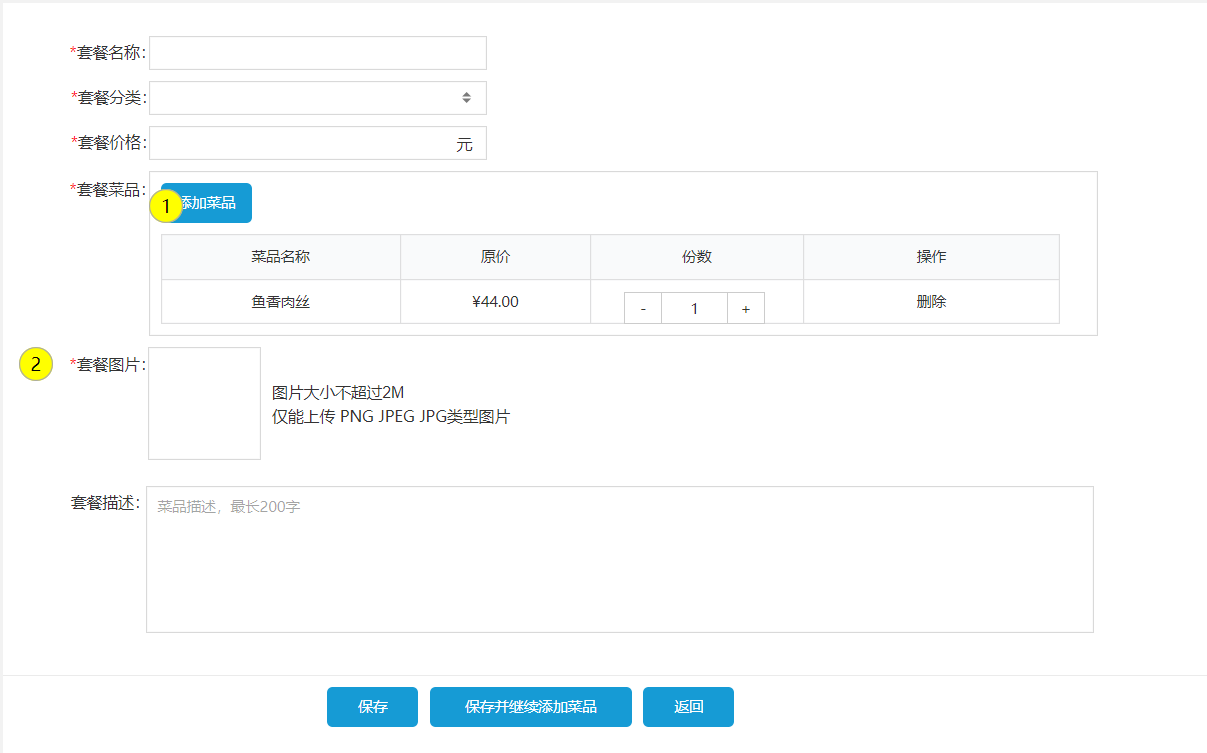

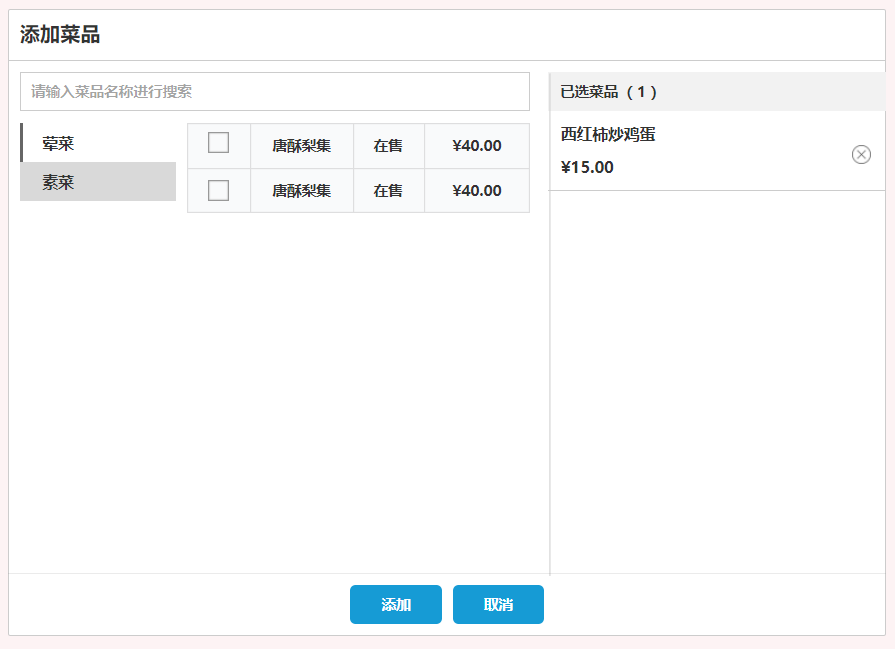

业务规则：

- 套餐名称唯一
- 套餐必须属于某个分类
- 套餐必须包含菜品
- 名称、分类、价格、图片为必填项
- 添加菜品窗口需要根据分类类型来展示菜品
- 新增的套餐默认为停售状态

接口设计（共涉及到4个接口）：

- 根据类型查询分类（已完成）
- 根据分类id查询菜品
- 图片上传（已完成）
- 新增套餐

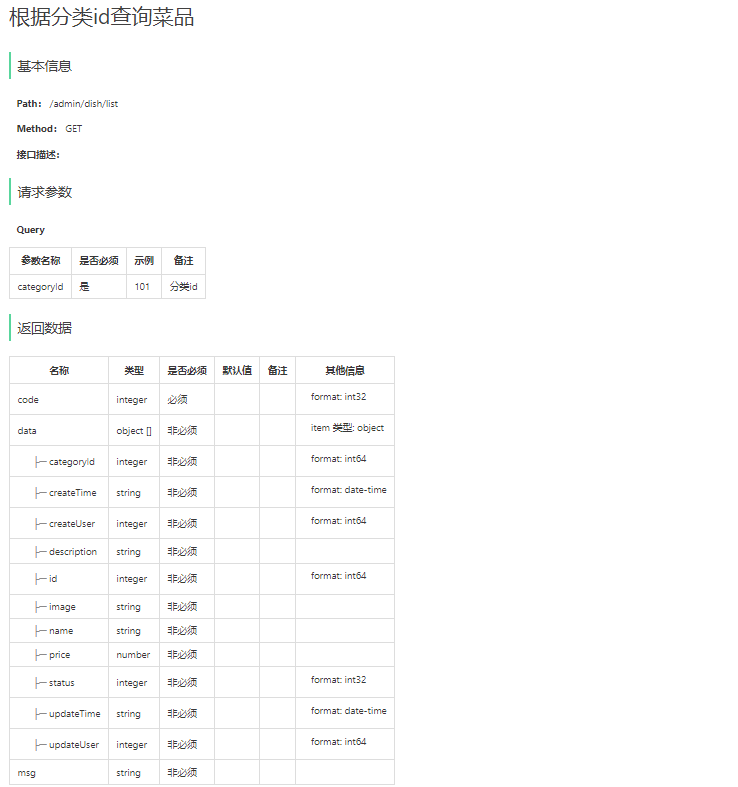

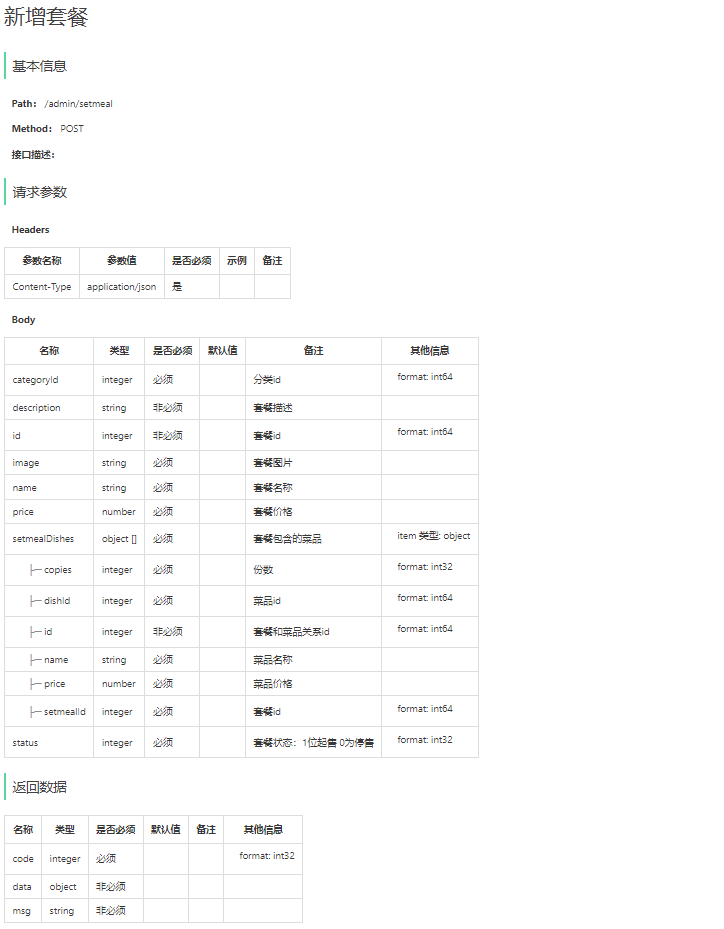

数据库设计：

setmeal表为套餐表，用于存储套餐的信息。具体表结构如下：

| 字段名      | 数据类型      | 说明         | 备注        |
| ----------- | ------------- | ------------ | ----------- |
| id          | bigint        | 主键         | 自增        |
| name        | varchar(32)   | 套餐名称     | 唯一        |
| category_id | bigint        | 分类id       | 逻辑外键    |
| price       | decimal(10,2) | 套餐价格     |             |
| image       | varchar(255)  | 图片路径     |             |
| description | varchar(255)  | 套餐描述     |             |
| status      | int           | 售卖状态     | 1起售 0停售 |
| create_time | datetime      | 创建时间     |             |
| update_time | datetime      | 最后修改时间 |             |
| create_user | bigint        | 创建人id     |             |
| update_user | bigint        | 最后修改人id |             |

setmeal_dish表为套餐菜品关系表，用于存储套餐和菜品的关联关系。具体表结构如下：

| 字段名     | 数据类型      | 说明     | 备注     |
| ---------- | ------------- | -------- | -------- |
| id         | bigint        | 主键     | 自增     |
| setmeal_id | bigint        | 套餐id   | 逻辑外键 |
| dish_id    | bigint        | 菜品id   | 逻辑外键 |
| name       | varchar(32)   | 菜品名称 | 冗余字段 |
| price      | decimal(10,2) | 菜品单价 | 冗余字段 |
| copies     | int           | 菜品份数 |          |


### 新增规则和两个请求（补充）

图片上传先返回URL，随后新增套餐请求带上image和setmealDishes。图片在OSS等文件存储，数据库保存URL；两个请求不属于一个数据库事务，保存套餐失败不等于图片已经自动删除。

套餐分类必须是存在、允许使用的套餐分类；选择菜品时按菜品分类查询当前启售菜品。界面限制不能替代服务端验证，直接调用接口仍应拒绝不存在的分类、菜品以及非法份数。

数据库表注明name唯一，要核对实际建表SQL是否建立唯一索引。可以先查重给友好提示，但并发新增仍要由数据库唯一约束兜底；修改名称时应排除当前套餐自身。

新增名称、分类、价格、图片和非空菜品集合为必填。价格使用BigDecimal并校验decimal(10,2)范围与小数精度；copies必须为正整数。多条重复dishId按业务合并或拒绝，不能无说明地重复插入。


### 1.2 代码实现

> **资料原文：** day04套餐管理参考答案。

#### 1.2.1 DishController

~~~java
/**
     * 根据分类id查询菜品
     * @param categoryId
     * @return
*/
@GetMapping("/list")
@ApiOperation("根据分类id查询菜品")
public Result<List<Dish>> list(Long categoryId){
    List<Dish> list = dishService.list(categoryId);
    return Result.success(list);
}
~~~

#### 1.2.2 DishService

~~~java
/**
     * 根据分类id查询菜品
     * @param categoryId
     * @return
*/
List<Dish> list(Long categoryId);
~~~

#### 1.2.3 DishServiceImpl

~~~java
/**
     * 根据分类id查询菜品
     * @param categoryId
     * @return
*/
public List<Dish> list(Long categoryId) {
    Dish dish = Dish.builder()
        .categoryId(categoryId)
        .status(StatusConstant.ENABLE)
        .build();
    return dishMapper.list(dish);
}
~~~

#### 1.2.4 DishMapper

~~~java
/**
     * 动态条件查询菜品
     * @param dish
     * @return
*/
List<Dish> list(Dish dish);
~~~

#### 1.2.5 DishMapper.xml

~~~xml
<select id="list" resultType="Dish" parameterType="Dish">
    select * from dish
    <where>
        <if test="name != null">
            and name like concat('%',#{name},'%')
        </if>
        <if test="categoryId != null">
            and category_id = #{categoryId}
        </if>
        <if test="status != null">
            and status = #{status}
        </if>
    </where>
    order by create_time desc
</select>
~~~

#### 1.2.6 SetmealController

~~~java
/**
 * 套餐管理
 */
@RestController
@RequestMapping("/admin/setmeal")
@Api(tags = "套餐相关接口")
@Slf4j
public class SetmealController {

    @Autowired
    private SetmealService setmealService;

    /**
     * 新增套餐
     * @param setmealDTO
     * @return
     */
    @PostMapping
    @ApiOperation("新增套餐")
    public Result save(@RequestBody SetmealDTO setmealDTO) {
        setmealService.saveWithDish(setmealDTO);
        return Result.success();
    }
}
~~~

#### 1.2.7 SetmealService

~~~java
public interface SetmealService {

    /**
     * 新增套餐，同时需要保存套餐和菜品的关联关系
     * @param setmealDTO
     */
    void saveWithDish(SetmealDTO setmealDTO);
}
~~~

#### 1.2.8 SetmealServiceImpl

~~~java
/**
 * 套餐业务实现
 */
@Service
@Slf4j
public class SetmealServiceImpl implements SetmealService {

    @Autowired
    private SetmealMapper setmealMapper;
    @Autowired
    private SetmealDishMapper setmealDishMapper;
    @Autowired
    private DishMapper dishMapper;

    /**
     * 新增套餐，同时需要保存套餐和菜品的关联关系
     * @param setmealDTO
     */
    @Transactional
    public void saveWithDish(SetmealDTO setmealDTO) {
        Setmeal setmeal = new Setmeal();
        BeanUtils.copyProperties(setmealDTO, setmeal);

        //向套餐表插入数据
        setmealMapper.insert(setmeal);

        //获取生成的套餐id
        Long setmealId = setmeal.getId();

        List<SetmealDish> setmealDishes = setmealDTO.getSetmealDishes();
        setmealDishes.forEach(setmealDish -> {
            setmealDish.setSetmealId(setmealId);
        });

        //保存套餐和菜品的关联关系
        setmealDishMapper.insertBatch(setmealDishes);
    }
}
~~~

#### 1.2.9 SetmealMapper

~~~java
/**
     * 新增套餐
     * @param setmeal
*/
@AutoFill(OperationType.INSERT)
void insert(Setmeal setmeal);
~~~

#### 1.2.10 SetmealMapper.xml

~~~xml
<insert id="insert" parameterType="Setmeal" useGeneratedKeys="true" keyProperty="id">
    insert into setmeal
    (category_id, name, price, status, description, image, create_time, update_time, create_user, update_user)
    values (#{categoryId}, #{name}, #{price}, #{status}, #{description}, #{image}, #{createTime}, #{updateTime},
    #{createUser}, #{updateUser})
</insert>
~~~

#### 1.2.11 SetmealDishMapper

~~~java
/**
     * 批量保存套餐和菜品的关联关系
     * @param setmealDishes
*/
void insertBatch(List<SetmealDish> setmealDishes);
~~~

#### 1.2.12 SetmealDishMapper.xml

~~~xml
<insert id="insertBatch" parameterType="list">
    insert into setmeal_dish
    (setmeal_id,dish_id,name,price,copies)
    values
    <foreach collection="setmealDishes" item="sd" separator=",">
        (#{sd.setmealId},#{sd.dishId},#{sd.name},#{sd.price},#{sd.copies})
    </foreach>
</insert>
~~~


### 主键回填、默认停售与批量参数（补充与勘误）

#### 1. 原代码没有强制默认停售

`BeanUtils.copyProperties`会把DTO.status复制到实体，原方法随后直接insert。DTO默认值、页面预设0和数据库默认值都不能替代后端控制；原INSERT显式写status，传null也不能依赖省略列的默认值。

在复制后、insert前明确控制新增id和状态：

```java
Setmeal setmeal = new Setmeal();
BeanUtils.copyProperties(setmealDTO, setmeal);
setmeal.setId(null); // 新增主键由数据库生成
setmeal.setStatus(StatusConstant.DISABLE); // 新增统一停售
setmealMapper.insert(setmeal);
Long setmealId = setmeal.getId();
```

这段替换原方法对应部分，不重复声明同名变量。插入SQL的 `useGeneratedKeys="true" keyProperty="id"` 必须保留：Mapper调用后生成的id回到同一setmeal对象，所有关系行再使用它。

#### 2. DTO传来的关系不是可信商品资料

原方法仅设置setmealId，name、price、dishId、copies都来自客户端。先核对每个dishId对应真实菜品、份数与重复项，关系的name和price按业务从服务端菜品记录确定，不盲信客户端快照。套餐自己的售价仍独立校验，不擅自改成菜品价格之和。

`setmealDishes`为null会在forEach报错；空集合会让INSERT生成没有VALUES内容的SQL。必须在写入前拒绝空套餐，新增和修改共用校验。关系id不从客户端继承，setmealId由后端统一写入。

#### 3. foreach集合名明确绑定

原XML使用 `collection="setmealDishes"`；Java单List参数还可能以list/collection或实际参数名暴露，受编译/MyBatis版本影响。推荐显式固定：

```java
void insertBatch(@org.apache.ibatis.annotations.Param("setmealDishes")
                 List<SetmealDish> setmealDishes);
```

XML继续使用setmealDishes。第03章也有SetmealDishMapper，合并同一个接口与XML；若已有方法的collection名称不同，要成套对齐，不能创建两份同名insertBatch映射。

#### 4. 事务与公共字段

原saveWithDish已带@Transactional，正确覆盖套餐和关系表两组写入。关系插入失败要让异常抛出，事务回滚；不catch后返回成功。AutoFill仅填审计字段，不校验状态、名称、分类和菜品。

确认Mapper被扫描、AutoFill切面能读取当前员工、实体有审计setter。`parameterType="Setmeal"`、`resultType="Dish"`依赖MyBatis别名配置；未配置时用 `com.sky.entity.Setmeal` 等完整名称。

#### 5. 按分类查询菜品

原dishService.list构造categoryId和status=1条件。请求缺失categoryId时动态SQL会省略分类条件并返回全部启售菜品；本选择窗口应要求categoryId有效，并核对分类类型。这个管理端方法可供后面用户浏览复用，但用户可见性规则要另行确认。


### 1.3 功能测试

> **资料原文：** day04套餐管理参考答案。

略


### 新增套餐验收矩阵（补充）

| 场景 | 核对结果 |
| --- | --- |
| 上传图片、添加两种菜品、保存 | setmeal一行、关系表两行、图片URL正确 |
| 新增请求带status=1 | 后端仍按规则保存为停售 |
| 主键回填 | 所有关系setmeal_id等于新套餐id |
| 同名或并发同名请求 | 唯一约束生效，业务提示合理 |
| 空菜品列表、份数0/负数、重复项 | 按校验规则拒绝，不创建空套餐 |
| 菜品不存在或快照价格被篡改 | 不采用伪造数据，按规则拒绝/重建 |
| 套餐分类不存在或类型错误 | 不写入错误分类 |
| 关系写入失败 | 套餐与关系全部回滚 |

答案原文只写“略”，这张表是补充验收步骤。用测试数据在接口文档和页面各测一次，并核对两张表和状态，不能只看保存成功提示。


## 2. 套餐分页查询

> **资料原文：** day04套餐管理参考答案。


### 2.1 需求分析和设计

> **资料原文：** day04套餐管理参考答案。

产品原型：

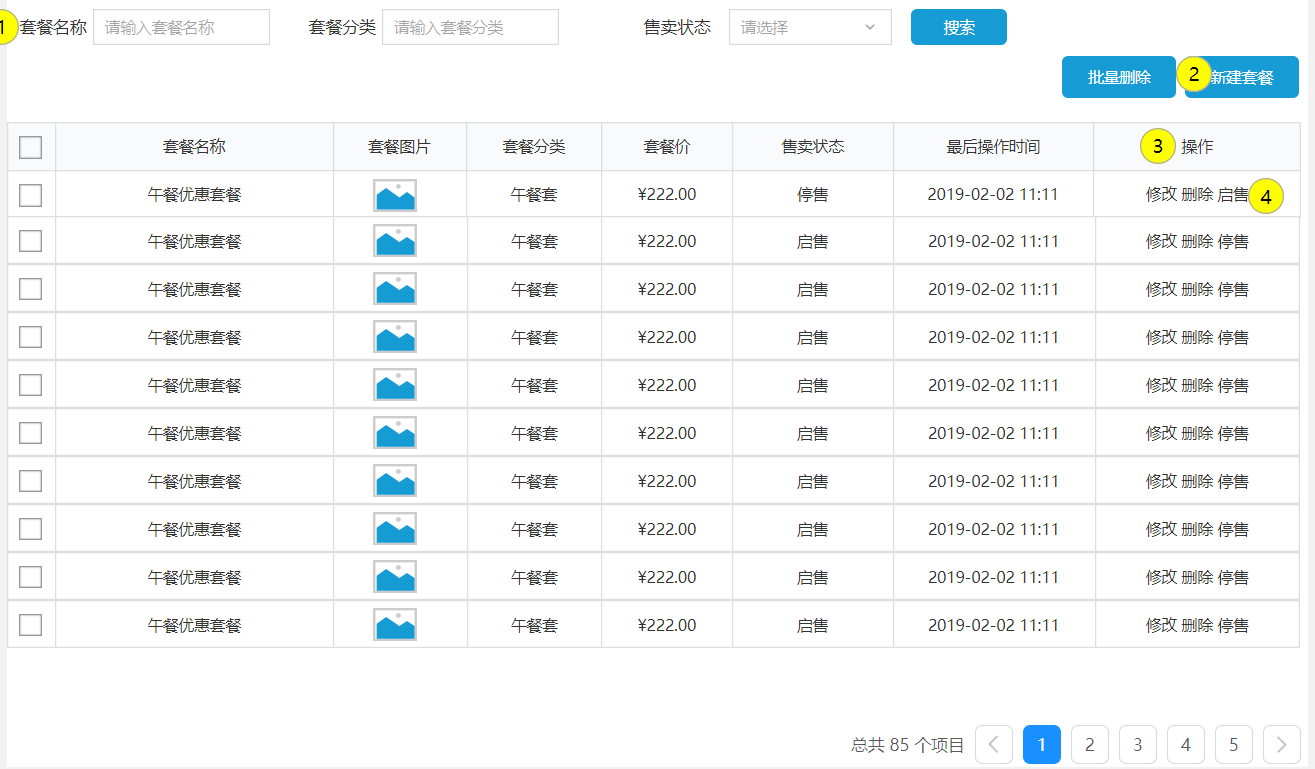

业务规则：

- 根据页码进行分页展示
- 每页展示10条数据
- 可以根据需要，按照套餐名称、分类、售卖状态进行查询

接口设计：

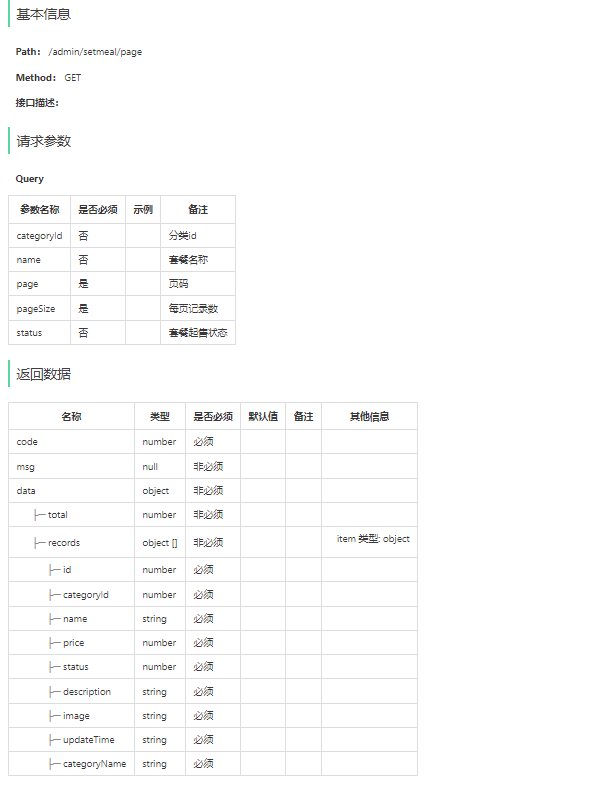


### 分页、条件和分类名称（补充）

页面默认每页10条，接口仍要约束page>=1、pageSize在允许范围内。name、categoryId、status是查询条件；不传表示不按该项过滤，status=0必须保留，不能用真假值判断而丢掉停售条件。

`categoryName`由setmeal与category左连接得到，不是套餐表的一列。左连接会保留分类缺失的历史套餐并给null名称；页面要按约定处理缺失分类，不误以为查询已经做了分类有效性校验。


### 2.2 代码实现

> **资料原文：** day04套餐管理参考答案。

#### 2.2.1 SetmealController

~~~java
/**
     * 分页查询
     * @param setmealPageQueryDTO
     * @return
*/
@GetMapping("/page")
@ApiOperation("分页查询")
public Result<PageResult> page(SetmealPageQueryDTO setmealPageQueryDTO) {
    PageResult pageResult = setmealService.pageQuery(setmealPageQueryDTO);
    return Result.success(pageResult);
}
~~~

#### 2.2.2 SetmealService

~~~java
/**
     * 分页查询
     * @param setmealPageQueryDTO
     * @return
*/
PageResult pageQuery(SetmealPageQueryDTO setmealPageQueryDTO);
~~~

#### 2.2.3 SetmealServiceImpl

~~~java
/**
     * 分页查询
     * @param setmealPageQueryDTO
     * @return
*/
public PageResult pageQuery(SetmealPageQueryDTO setmealPageQueryDTO) {
    int pageNum = setmealPageQueryDTO.getPage();
    int pageSize = setmealPageQueryDTO.getPageSize();

    PageHelper.startPage(pageNum, pageSize);
    Page<SetmealVO> page = setmealMapper.pageQuery(setmealPageQueryDTO);
    return new PageResult(page.getTotal(), page.getResult());
}
~~~

#### 2.2.4 SetmealMapper

~~~java
/**
     * 分页查询
     * @param setmealPageQueryDTO
     * @return
*/
Page<SetmealVO> pageQuery(SetmealPageQueryDTO setmealPageQueryDTO);
~~~

#### 2.2.5 SetmealMapper.xml

~~~xml
<select id="pageQuery" resultType="com.sky.vo.SetmealVO">
    select
    	s.*,c.name categoryName
    from
    	setmeal s
    left join
    	category c
    on
    	s.category_id = c.id
    <where>
        <if test="name != null">
            and s.name like concat('%',#{name},'%')
        </if>
        <if test="status != null">
            and s.status = #{status}
        </if>
        <if test="categoryId != null">
            and s.category_id = #{categoryId}
        </if>
    </where>
    order by s.create_time desc
</select>
~~~


### PageHelper与分页稳定性（补充与勘误）

原 `PageHelper.startPage` 后紧跟setmealMapper.pageQuery，分页返回 `total` 和 `records`。startPage只影响随后匹配的查询；不要在两者之间插入别的Mapper查询，否则分页可能落到错误SQL上。

分页查询DTO必须校验页码、页大小和status=0/1。资料完整版的SetmealPageQueryDTO.categoryId是Integer，而分类主键与其他实体使用Long，实际工程建议统一Long，避免大id无法绑定；这是资料类型改进，不把原文件描述成Long。

name空串/空白可先规范为null，避免生成没有意义的 `like '%%'`。SQL已经使用 `#{}` 绑定值，不应改成 `${}` 拼接客户端查询条件。

原排序仅 `s.create_time desc`，同时间多行的顺序可能不稳定，可加 `s.id desc`作为次级排序：

```sql
order by s.create_time desc, s.id desc
```

分页VO包含categoryName；列表通常不需要每行查setmealDishes，避免无意添加N+1查询。查看详情再查询完整菜品关系。


### 2.3 功能测试

> **资料原文：** day04套餐管理参考答案。

略


### 分页查询验收矩阵（补充）

| 场景 | 核对结果 |
| --- | --- |
| 超过10条记录，查看第1/2页 | total正确，records为本页，排序稳定 |
| name模糊、categoryId、status组合 | 仅匹配全部给定条件 |
| status=0 | 正确筛选停售，不能被当成未传 |
| 空结果或超出末页 | 返回空records，total语义一致 |
| page<=0、pageSize过大 | 被参数校验拒绝或按明确约定规范 |
| 查询categoryName | 与分类表名称一致 |

核对接口响应与SQL；前端有分页按钮不能证明total、本页数量和筛选条件正确。


## 3. 删除套餐

> **资料原文：** day04套餐管理参考答案。


### 3.1 需求分析和设计

> **资料原文：** day04套餐管理参考答案。

产品原型：

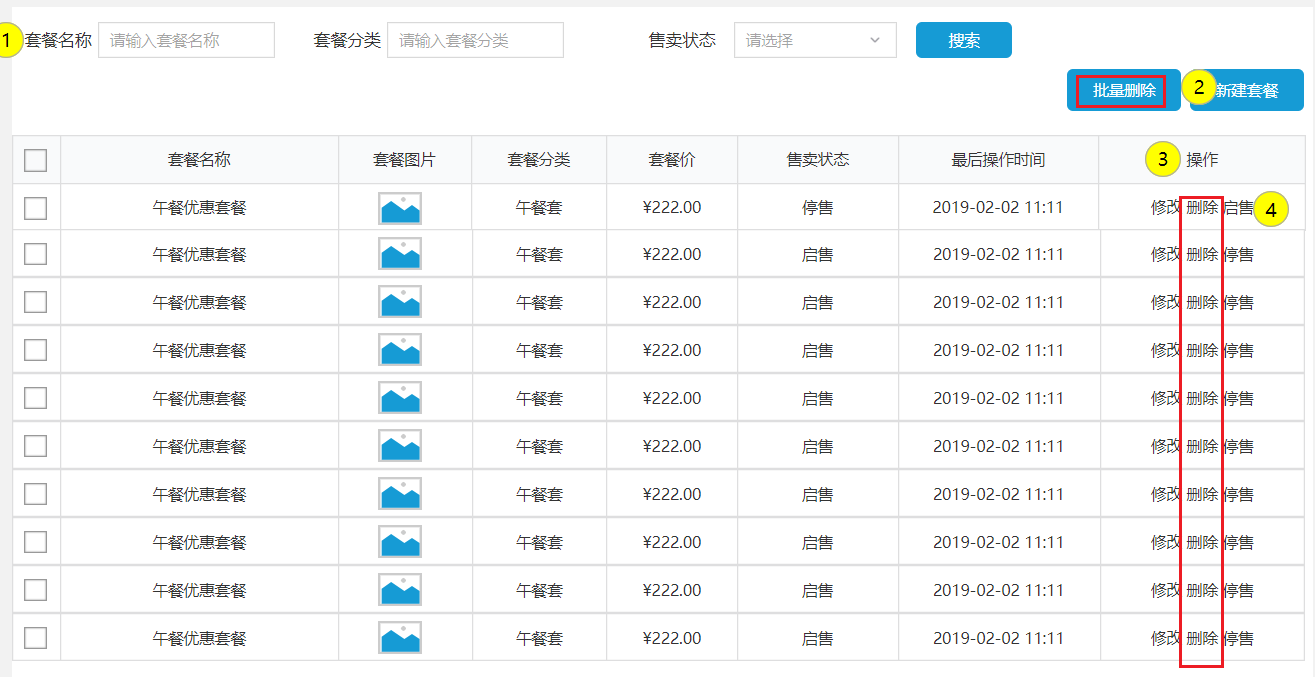

业务规则：

- 可以一次删除一个套餐，也可以批量删除套餐
- 起售中的套餐不能删除

接口设计：

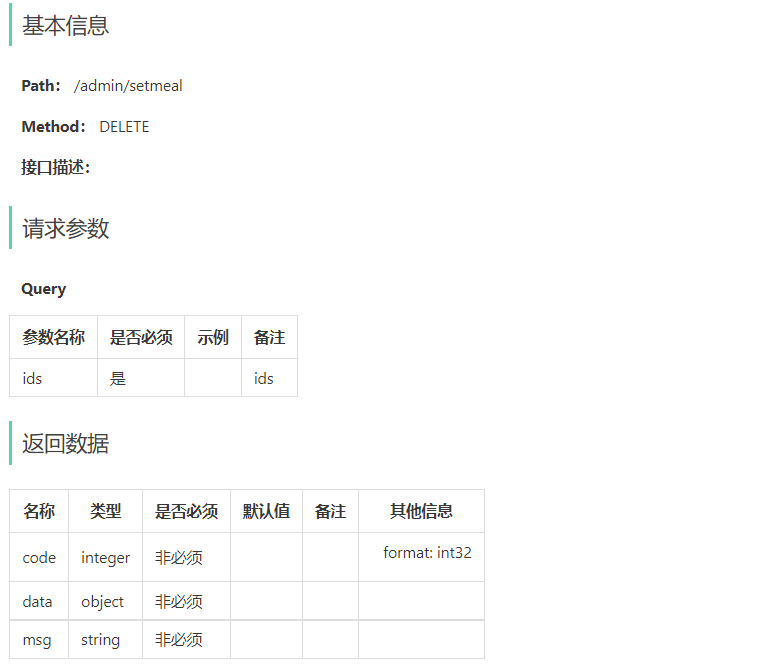


### 删除的整体规则（补充）

单删和批删都用ids列表。资料要求起售套餐不能删除；一批中有一个起售项，应整批拒绝，而不是删除一部分再返回失败。停售后才能删除，套餐及关系表一起处理。

本章表结构描述逻辑外键，业务代码维护关系；如果工程后来加了数据库外键，需按约束先删子表再删主表。删除套餐不删除关联菜品和口味，不影响其他套餐引用这些菜品。


### 3.2 代码实现

> **资料原文：** day04套餐管理参考答案。

#### 3.2.1 SetmealController

~~~java
/**
     * 批量删除套餐
     * @param ids
     * @return
*/
@DeleteMapping
@ApiOperation("批量删除套餐")
public Result delete(@RequestParam List<Long> ids){
    setmealService.deleteBatch(ids);
    return Result.success();
}
~~~

#### 3.2.2 SetmealService

~~~java
/**
     * 批量删除套餐
     * @param ids
*/
void deleteBatch(List<Long> ids);
~~~

#### 3.2.3 SetmealServiceImpl

~~~java
/**
     * 批量删除套餐
     * @param ids
*/
@Transactional
public void deleteBatch(List<Long> ids) {
    ids.forEach(id -> {
        Setmeal setmeal = setmealMapper.getById(id);
        if(StatusConstant.ENABLE == setmeal.getStatus()){
            //起售中的套餐不能删除
            throw new DeletionNotAllowedException(MessageConstant.SETMEAL_ON_SALE);
        }
    });

    ids.forEach(setmealId -> {
        //删除套餐表中的数据
        setmealMapper.deleteById(setmealId);
        //删除套餐菜品关系表中的数据
        setmealDishMapper.deleteBySetmealId(setmealId);
    });
}
~~~

#### 3.2.4 SetmealMapper

~~~java
/**
     * 根据id查询套餐
     * @param id
     * @return
*/
@Select("select * from setmeal where id = #{id}")
Setmeal getById(Long id);

/**
     * 根据id删除套餐
     * @param setmealId
*/
@Delete("delete from setmeal where id = #{id}")
void deleteById(Long setmealId);
~~~

#### 3.2.5 SetmealDishMapper

~~~java
/**
     * 根据套餐id删除套餐和菜品的关联关系
     * @param setmealId
*/
@Delete("delete from setmeal_dish where setmeal_id = #{setmealId}")
void deleteBySetmealId(Long setmealId);
~~~


### 删除校验、参数绑定与事务（补充与勘误）

原getById返回null时 `setmeal.getStatus()`会空指针。先规范ids：非空、正数、去重、限制批量大小，然后确认每个目标存在、状态合法且停售，再执行删除。

原比较常量与Integer会自动拆箱，status=null也可能报错。可用 `Integer.valueOf(StatusConstant.ENABLE).equals(setmeal.getStatus())`检查起售；未知/null状态应作为数据异常拒绝，不据此当作可删。

原Mapper声明 `deleteById(Long setmealId)`，SQL却使用 `#{id}`。单个简单参数可能被MyBatis整体绑定，不把它说成一定报错；为减少版本/代理差异，建议明确同名：

```java
@Delete("delete from setmeal where id = #{id}")
int deleteById(@org.apache.ibatis.annotations.Param("id") Long id);
```

若返回int，业务层可核对影响行数。同理，多个参数和List都应明确命名。Controller可写 `@RequestParam("ids") List<Long> ids`，避免依赖编译器保留参数名。

原deleteBatch已带@Transactional，保留。校验与删除期间别人可能起售同一套餐，事务本身不自动消除这个竞争；需要按既定锁定顺序协调起售、修改和删除，或在DELETE条件中再次限制status并核对行数，失败抛异常回滚。

删除顺序应根据真实数据库约束确定；使用物理外键时先关系后套餐。这样不留下孤立关系，也不误删dish和dish_flavor。


### 3.3 功能测试

> **资料原文：** day04套餐管理参考答案。

略


### 删除套餐验收矩阵（补充）

| 场景 | 核对结果 |
| --- | --- |
| 删除一个停售套餐 | 套餐与关系删除，菜品/口味保留 |
| 批删多个停售套餐 | 全部成功，无残留关系 |
| 批次包含起售套餐 | 全批拒绝，任何目标都不被删 |
| 不存在id、空列表、重复id | 按规范返回错误/去重，不空指针 |
| 子表或主表删除失败 | 整个事务回滚 |
| 并发起售与删除 | 不能删除刚起售的套餐或返回假成功 |

接口文档使用 `ids=1,2`，页面单删/批删各验一次，再查套餐、关系、菜品三类数据。


## 4. 修改套餐

> **资料原文：** day04套餐管理参考答案。


### 4.1 需求分析和设计

> **资料原文：** day04套餐管理参考答案。

产品原型：

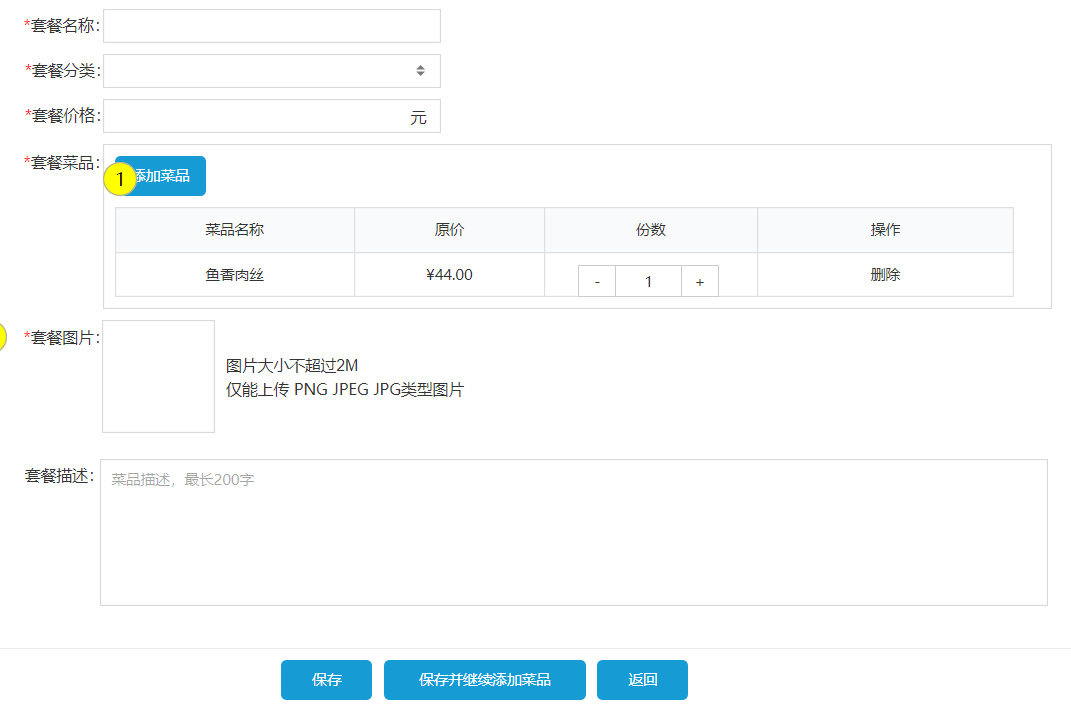

接口设计（共涉及到5个接口）：

- 根据id查询套餐
- 根据类型查询分类（已完成）
- 根据分类id查询菜品（已完成）
- 图片上传（已完成）
- 修改套餐

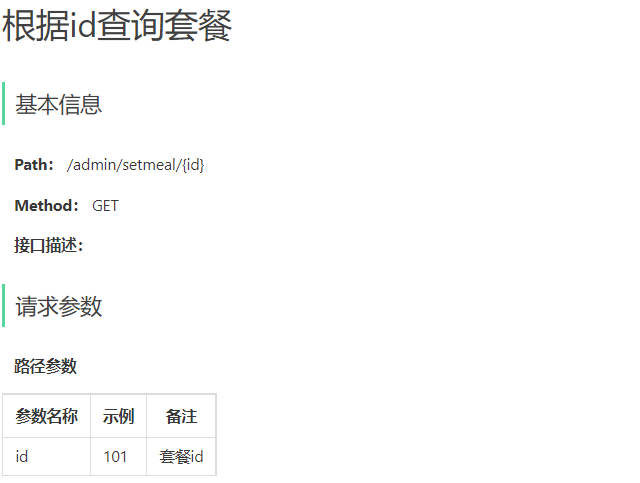

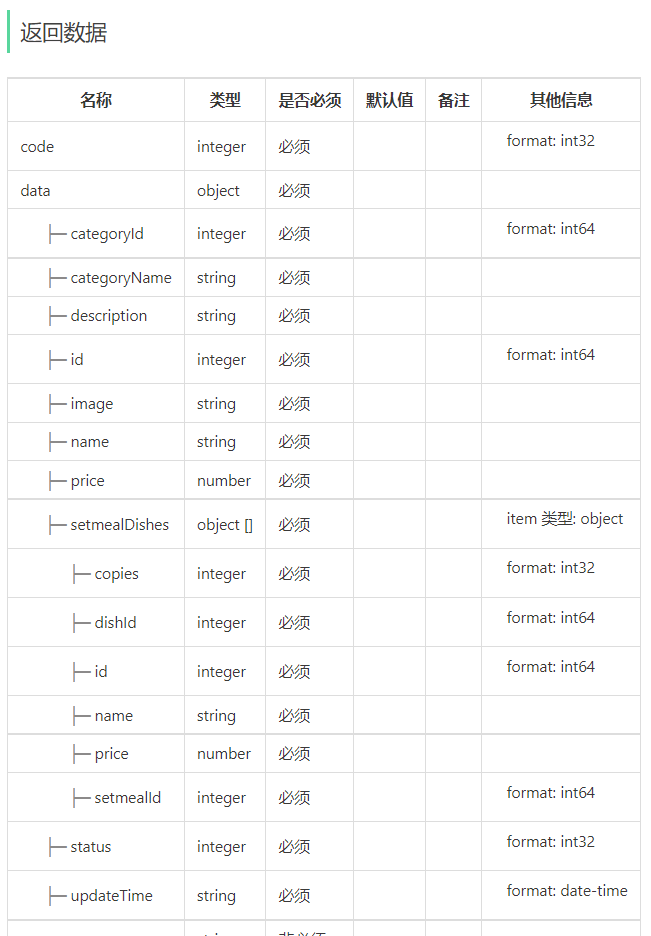


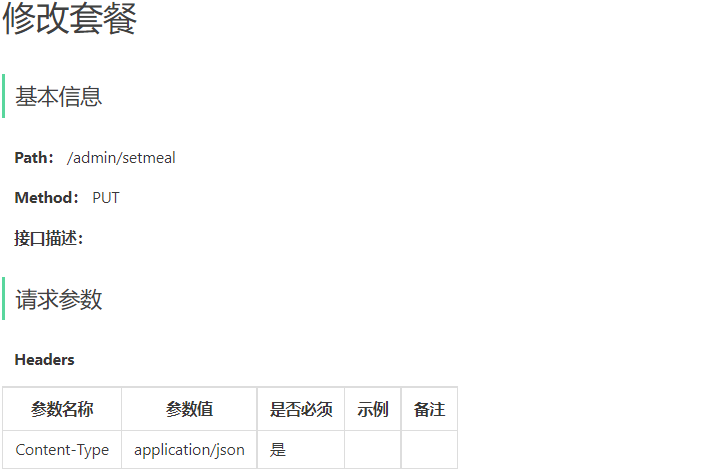

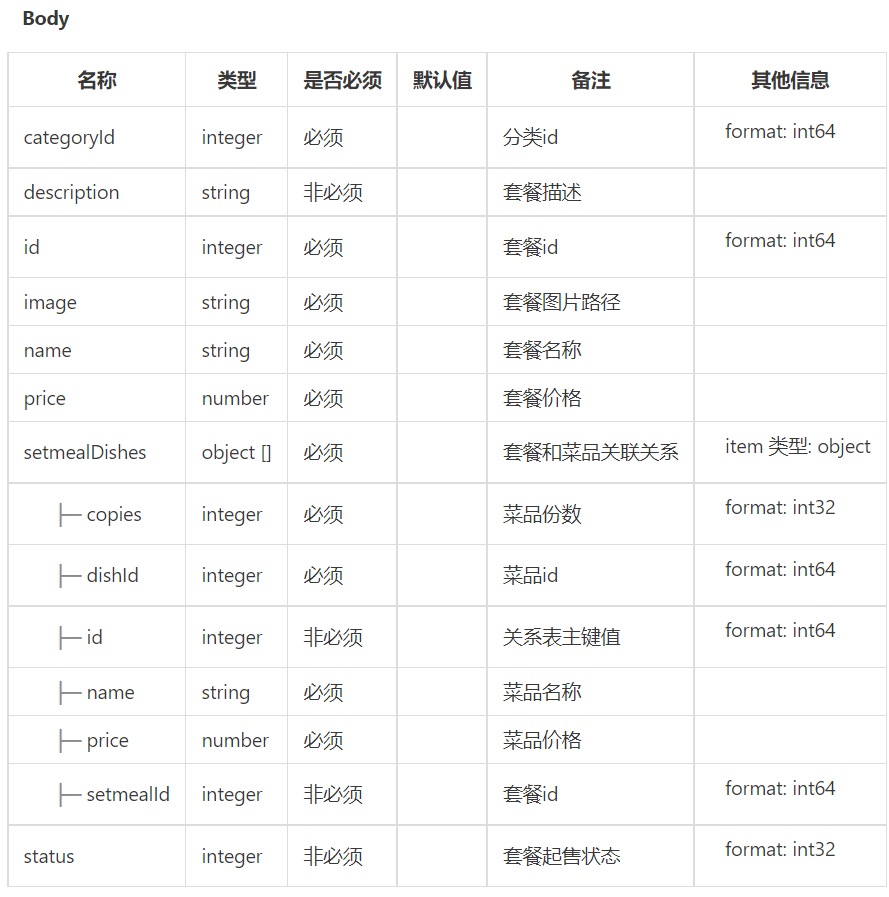

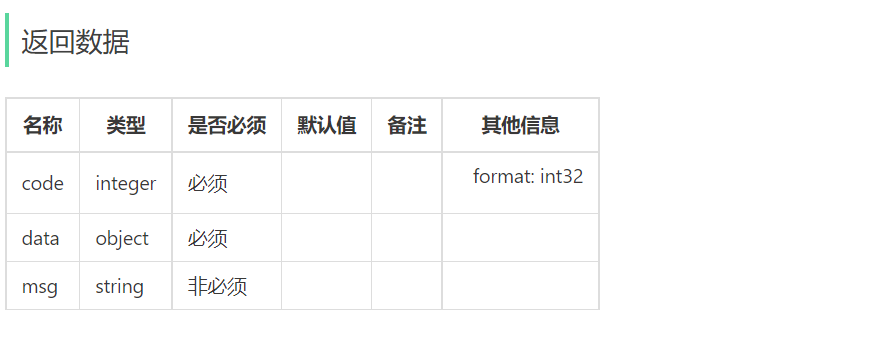


### 回显与整体替换关系（补充）

回显需要套餐基础字段和setmealDishes完整列表。明细里dishId标识菜品，id标识关系行，二者不同；setmealId属于当前套餐，不允许客户端把新关系挂到其他套餐。

资料的修改是“全量表单”语义：先更新套餐，再删除全部旧关系、重新插入新列表。请求必须带完整非空列表，不是只提交变化的一条菜品。只改名称时也需保留表单中的全部菜品，或另设计独立的局部修改接口。


### 4.2 代码实现

> **资料原文：** day04套餐管理参考答案。

#### 4.2.1 SetmealController

~~~java
/**
     * 根据id查询套餐，用于修改页面回显数据
     *
     * @param id
     * @return
*/
@GetMapping("/{id}")
@ApiOperation("根据id查询套餐")
public Result<SetmealVO> getById(@PathVariable Long id) {
    SetmealVO setmealVO = setmealService.getByIdWithDish(id);
    return Result.success(setmealVO);
}

/**
     * 修改套餐
     *
     * @param setmealDTO
     * @return
*/
@PutMapping
@ApiOperation("修改套餐")
public Result update(@RequestBody SetmealDTO setmealDTO) {
    setmealService.update(setmealDTO);
    return Result.success();
}
~~~

#### 4.2.2 SetmealService

~~~java
/**
     * 根据id查询套餐和关联的菜品数据
     * @param id
     * @return
*/
SetmealVO getByIdWithDish(Long id);

/**
     * 修改套餐
     * @param setmealDTO
*/
void update(SetmealDTO setmealDTO);
~~~

#### 4.2.3 SetmealServiceImpl

~~~java
/**
     * 根据id查询套餐和套餐菜品关系
     *
     * @param id
     * @return
*/
public SetmealVO getByIdWithDish(Long id) {
    Setmeal setmeal = setmealMapper.getById(id);
    List<SetmealDish> setmealDishes = setmealDishMapper.getBySetmealId(id);

    SetmealVO setmealVO = new SetmealVO();
    BeanUtils.copyProperties(setmeal, setmealVO);
    setmealVO.setSetmealDishes(setmealDishes);
    
    return setmealVO;
}

/**
     * 修改套餐
     *
     * @param setmealDTO
*/
@Transactional
public void update(SetmealDTO setmealDTO) {
    Setmeal setmeal = new Setmeal();
    BeanUtils.copyProperties(setmealDTO, setmeal);

    //1、修改套餐表，执行update
    setmealMapper.update(setmeal);

    //套餐id
    Long setmealId = setmealDTO.getId();

    //2、删除套餐和菜品的关联关系，操作setmeal_dish表，执行delete
    setmealDishMapper.deleteBySetmealId(setmealId);

    List<SetmealDish> setmealDishes = setmealDTO.getSetmealDishes();
    setmealDishes.forEach(setmealDish -> {
        setmealDish.setSetmealId(setmealId);
    });
    //3、重新插入套餐和菜品的关联关系，操作setmeal_dish表，执行insert
    setmealDishMapper.insertBatch(setmealDishes);
}
~~~

#### 4.2.4 SetmealDishMapper

~~~java
	/**
     * 根据套餐id查询套餐和菜品的关联关系
     * @param setmealId
     * @return
     */
    @Select("select * from setmeal_dish where setmeal_id = #{setmealId}")
    List<SetmealDish> getBySetmealId(Long setmealId);
~~~


### 回显判空、缺失update与状态入口（补充与勘误）

#### 1. 查询不到套餐时先返回业务错误

原 `BeanUtils.copyProperties(setmeal, setmealVO)`要求源对象存在。getById返回null时先处理不存在，不能继续复制。关系列表没有数据应按空列表或数据异常规则处理，不伪造菜品。

#### 2. 参考答案调用update但未给出实现

参考答案的 `setmealMapper.update(setmeal)`依赖已有Mapper声明和XML。笔记前面的“资料补全”单元从同一压缩包day12项目完整版提供 `@AutoFill(OperationType.UPDATE)`声明与动态SQL；按现有工程合并，保留INSERT/分页等已有映射，不能覆盖整个Mapper。

补全的update只修改非null字段，因此description=null一般表示不改，空字符串可以表示清空描述；字段清空的语义要和表单约定一致。AutoFill填审计值，SQL仍需写update_time/update_user。

#### 3. 普通修改不能绕过起售校验

DTO.status会被BeanUtils复制。若普通update接受status=1并直接更新，就能绕过“套餐内菜品全部启售”的专用检查。可在普通编辑中从数据库保留原状态，再统一调用起售规则；编辑已起售套餐的菜品组成时，要选择禁止编辑、自动停售或重新校验后保持起售，并在事务中执行。

```java
Setmeal existing = setmealMapper.getById(setmealDTO.getId());
if (existing == null) {
    throw new IllegalArgumentException("套餐不存在");
}
Setmeal setmeal = new Setmeal();
BeanUtils.copyProperties(setmealDTO, setmeal);
setmeal.setStatus(existing.getStatus()); // 状态入口按业务统一控制
```

这是原update开头的替换片段，不能仅贴这段就认为已处理已起售套餐换入停售菜品的全部情况。前面新增的名称、分类、价格、菜品、copies校验在修改中同样适用。

#### 4. 三组写入同一事务

```text
更新setmeal → 删除旧setmeal_dish → 插入新setmeal_dish
    任一步失败 → 套餐字段与旧关系一起回滚
```

原update带@Transactional正确，保留。新关系setmealId由后端设置，id由数据库生成；在已验证集合上替换，防止空集合破坏套餐组成。并发编辑要按业务使用版本或锁，防止后提交的旧页面覆盖新内容。

#### 5. 完整版的回显方案与day04不同

day04先查套餐、再查关系；资料day12完整版用 `getByIdWithDish` 的JOIN/resultMap一次回显。二者都可实现；选择与当前接口一致的一种，不同时返回两套冲突结果。本笔记原答案仍保留day04的两次查询写法。


### 4.3 功能测试

> **资料原文：** day04套餐管理参考答案。

略


### 修改套餐验收矩阵（补充）

| 场景 | 核对结果 |
| --- | --- |
| 回显存在套餐 | 基础信息、dishId、copies等完整 |
| 回显不存在id | 业务错误，不BeanUtils异常 |
| 换入/删除一项菜品并保存 | 关系列表与完整请求一致，无旧项残留 |
| 修改名称为已有名称 | 唯一规则生效，原套餐不被破坏 |
| 空列表、伪造状态、非法菜品份数 | 校验拒绝，不能绕过起售规则 |
| 新关系插入失败 | 原字段、旧关系全部回滚 |
| 并发编辑或编辑起售套餐 | 遵守版本/锁及售卖状态策略 |

重点核对关系表而不只是基础字段；删除旧关系再插入新关系会生成新关系id，不应据此认为历史关系id必须保留。


## 5. 起售停售套餐

> **资料原文：** day04套餐管理参考答案。


### 5.1 需求分析和设计

> **资料原文：** day04套餐管理参考答案。

产品原型：

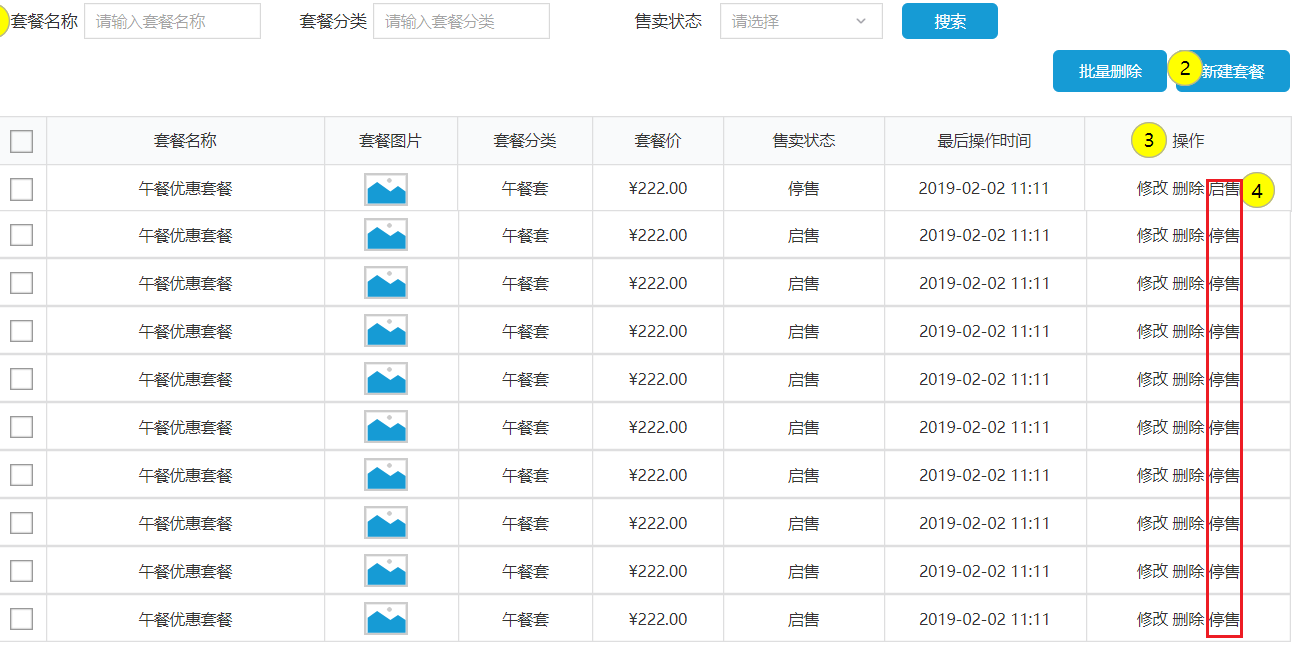

业务规则：

- 可以对状态为起售的套餐进行停售操作，可以对状态为停售的套餐进行起售操作
- 起售的套餐可以展示在用户端，停售的套餐不能展示在用户端
- 起售套餐时，如果套餐内包含停售的菜品，则不能起售

接口设计：

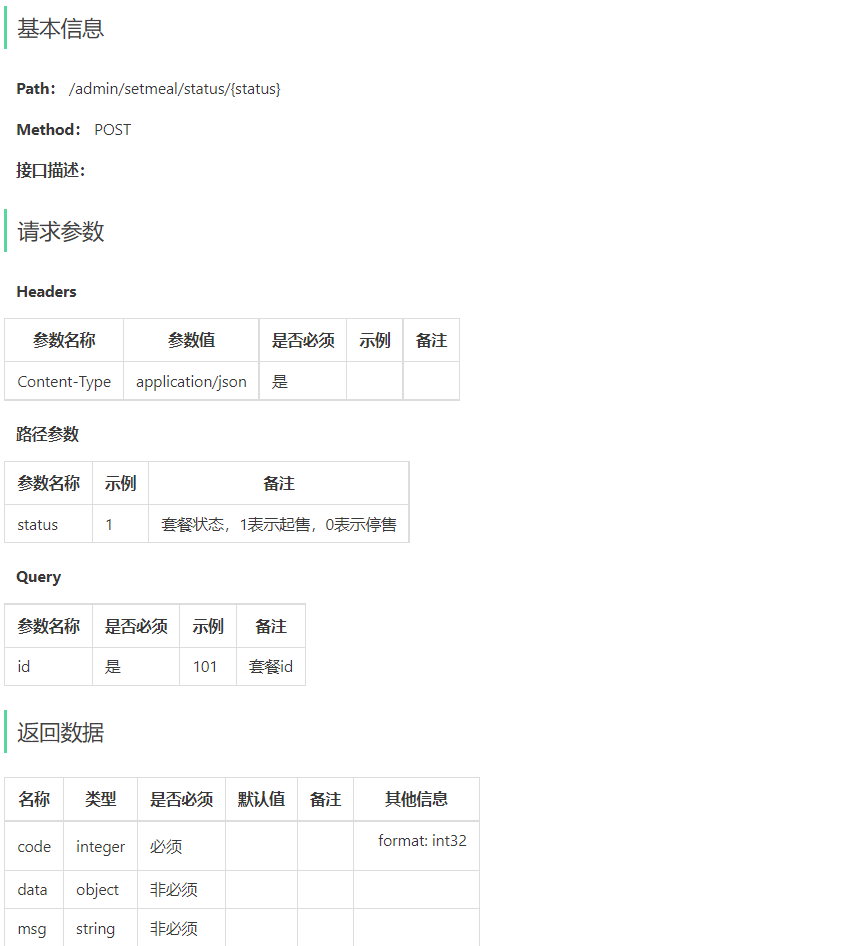


### 套餐可售与菜品可售的依赖（补充）

套餐起售需要套餐存在、组成非空、所有关联菜品存在且处于起售状态。停售则只改变套餐本身，不把其包含的菜品一起停售；一个菜品还可能属于其他套餐或单独售卖。

“起售才能显示在用户端”是需求规则，本章代码主要实现管理端状态切换，不能只改状态后就认定用户查询已过滤。第06章用户端列表会明确带status=1，还应核对分类可用性。


### 5.2 代码实现

> **资料原文：** day04套餐管理参考答案。

#### 5.2.1 SetmealController

~~~java
/**
     * 套餐起售停售
     * @param status
     * @param id
     * @return
*/
@PostMapping("/status/{status}")
@ApiOperation("套餐起售停售")
public Result startOrStop(@PathVariable Integer status, Long id) {
    setmealService.startOrStop(status, id);
    return Result.success();
}
~~~

#### 5.2.2 SetmealService

~~~java
/**
     * 套餐起售、停售
     * @param status
     * @param id
*/
void startOrStop(Integer status, Long id);
~~~

#### 5.2.3 SetmealServiceImpl

~~~java
/**
     * 套餐起售、停售
     * @param status
     * @param id
*/
public void startOrStop(Integer status, Long id) {
    //起售套餐时，判断套餐内是否有停售菜品，有停售菜品提示"套餐内包含未启售菜品，无法启售"
    if(status == StatusConstant.ENABLE){
        //select a.* from dish a left join setmeal_dish b on a.id = b.dish_id where b.setmeal_id = ?
        List<Dish> dishList = dishMapper.getBySetmealId(id);
        if(dishList != null && dishList.size() > 0){
            dishList.forEach(dish -> {
                if(StatusConstant.DISABLE == dish.getStatus()){
                    throw new SetmealEnableFailedException(MessageConstant.SETMEAL_ENABLE_FAILED);
                }
            });
        }
    }

    Setmeal setmeal = Setmeal.builder()
        .id(id)
        .status(status)
        .build();
    setmealMapper.update(setmeal);
}
~~~

#### 5.2.4 DishMapper

~~~java
/**
     * 根据套餐id查询菜品
     * @param setmealId
     * @return
*/
@Select("select a.* from dish a left join setmeal_dish b on a.id = b.dish_id where b.setmeal_id = #{setmealId}")
List<Dish> getBySetmealId(Long setmealId);
~~~


### 起售前的完整校验与并发（补充与勘误）

#### 1. 状态与目标必须合法

原status=null在 `status == StatusConstant.ENABLE`时可能空指针，2或其他值会直接被更新进数据库。先校验status只允许0/1，id为正且套餐存在，再执行逻辑。参数显式绑定更清晰：

```java
@PostMapping("/status/{status}")
public Result startOrStop(@PathVariable("status") Integer status,
                          @RequestParam("id") Long id) {
    setmealService.startOrStop(status, id);
    return Result.success();
}
```

无需为这个Query参数另加@RequestBody；资料截图虽注明JSON Content-Type，实际控制器仍从查询参数读取id。

#### 2. 空套餐和缺失菜品不能放行

原 `dishMapper.getBySetmealId` 从dish出发LEFT JOIN关系表，WHERE再限定b.setmeal_id，效果只返回仍存在的关联菜品。空关系和指向已删除菜品的关系都可能得到空/不完整列表；原代码只在列表非空时检查停售，其余直接起售。

应先读取全部setmeal_dish关系，拒绝空列表，逐项或批量读取菜品并核对返回集合覆盖全部dishId；所有菜品状态都必须等于ENABLE，未知/null状态也不能当作可售。不要只比较结果行数而忽略重复关联。

#### 3. 事务不等于并发不变式已保证

原startOrStop没有@Transactional。启售过程的“查菜品→改套餐”可能与菜品停售、删除、套餐编辑同时发生。需用明确的事务与统一锁定/条件策略协调这些入口；仅加事务注解仍不能宣称套餐绝不会包含停售菜品。

同一资料.rar的day12完整版DishServiceImpl.startOrStop在事务内将停售菜品关联的套餐也停售，这能补充理解状态依赖，但不是day04答案已经展示的功能。所有更新分支都要遵循同一规则和锁定顺序，避免相互竞争。

#### 4. 后续缓存章节的衔接

第07章增加套餐缓存之后，新增、修改、删除、起售停售均需使相关缓存失效，菜品停售联动套餐时也要覆盖。不能只让数据库改正确而继续给用户返回旧缓存；本章先完成数据库业务规则。


### 5.3 功能测试

> **资料原文：** day04套餐管理参考答案。

略


### 起售停售验收矩阵（补充）

| 场景 | 核对结果 |
| --- | --- |
| 全部菜品启售的有效套餐 | 可起售，status=1 |
| 包含一个停售菜品 | 起售拒绝，套餐原状态不变 |
| 空关系或关联菜品不存在 | 拒绝起售，不把空查询当合法 |
| status为空或不是0/1、套餐不存在 | 参数/业务错误，不写异常状态 |
| 套餐停售 | status=0，菜品和其他套餐不变 |
| 普通修改提交status=1 | 不能绕过专用起售校验 |
| 菜品并发停售、套餐并发启售 | 按协调策略保持可售规则 |
| 用户端浏览/缓存 | 只显示合法启售套餐，旧缓存不继续展示 |

接口文档先切换0/1，页面再联调；使用测试数据检查setmeal、dish、setmeal_dish，并明确哪些联动属于后续工程补全。


## 复习速查、排错与本章验收（补充）

| 知识点 | 核心记忆 |
| --- | --- |
| 多对多 | 套餐↔菜品由setmeal_dish关联，口味仍属于dish_flavor |
| DTO/实体/VO | 请求携带集合，实体映射表，VO承载分类名和回显关系 |
| 新增 | 默认停售，主键回填后才设置所有关系setmealId |
| 批量参数 | @Param名称与foreach collection成套一致 |
| 分页 | startPage紧邻查询，total与records不同，排序需稳定 |
| 删除 | 全批先验证，起售不可删，两表事务，菜品不跟着删 |
| 修改 | 全量替换关系，失败恢复旧数据，状态不能绕过起售 |
| 起售 | 套餐非空、全部菜品存在且启售，空查询不能放行 |
| 并发 | 事务负责提交/回滚，锁/条件/版本负责操作协调 |

### 常见问题排查

| 表现 | 先检查 |
| --- | --- |
| 新增套餐保存为起售/null | DTO.status是否被直接复制，后端是否设置0 |
| 关系setmeal_id为空 | useGeneratedKeys、keyProperty及回填对象 |
| foreach找不到setmealDishes | Mapper @Param与collection是否一致 |
| 空集合插入SQL报错 | 保存前是否拒绝空菜品列表 |
| 分页total不对 | startPage后的第一条查询是否正确 |
| 分类筛选大id绑定失败 | SetmealPageQueryDTO.categoryId是否仍为Integer |
| update映射找不到 | 是否合并SetmealMapper.update和XML |
| 删除/回显不存在id报异常 | getById返回null是否先处理 |
| 普通编辑后突然起售 | 是否接受了DTO.status绕过专用入口 |
| 缺菜品仍能起售 | 是否完整核对关系及实际菜品集合 |
| 数据库改了页面还没变 | 响应/刷新或后续章节缓存失效是否正确 |

### 跟练验收清单

- [ ] 实战题五个功能均有需求、接口、表关系和测试记录。
- [ ] 复用分类与图片上传，正确区分菜品分类1和套餐分类2。
- [ ] DTO/VO/实体和Mapper所需类型存在，update方法与XML已补齐。
- [ ] 新增在服务端保证停售，名称唯一、价格和菜品份数校验完整。
- [ ] 套餐主键回填，关系数据由后端确定，空列表不写入。
- [ ] 分页条件、PageHelper调用、total/records及排序正确。
- [ ] 删除批次全量验证、两表回滚、无孤立关系、不删菜品。
- [ ] 回显判空，修改整体替换关系，失败保留原数据。
- [ ] 普通修改不能绕过起售规则，所有状态只允许0/1。
- [ ] 空套餐/缺失菜品不能起售，并发操作有明确协调策略。
- [ ] 接口文档和前后端联调都核对数据库结果。

### 自测问题

1. 为什么套餐与菜品需要setmeal_dish而不是在setmeal保存一个dishId？
2. 套餐价、菜品冗余单价、copies分别表示什么？
3. useGeneratedKeys和keyProperty为什么决定关系表能否正确写入？
4. 页面默认status=0，为什么后端还要强制新增停售？
5. @AutoFill能否替代名称、分类和售卖状态校验？
6. PageHelper.startPage与Mapper查询之间为什么不能加别的查询？
7. 批删中包含一个起售套餐应怎样处理，为什么要事务？
8. 修改时删除旧关系再插入，插入失败应如何恢复？
9. 普通编辑接受status=1会绕过哪个规则？
10. 原getBySetmealId返回空列表，为什么不能直接允许起售？
11. 给startOrStop加事务为什么仍需考虑菜品并发停售？
12. 后续有缓存后，状态切换和菜品联动需要怎样失效缓存？

这份笔记完成资料整理、代码片段核对与离线排版验证；实际后端接口、数据库事务和页面联调按验收矩阵在测试环境执行。
